# 02. PHÂN LOẠI EMAIL BẰNG QUY TẮC TỪ KHÓA (RULE-BASED)

**Thành viên:** Nguyễn Kiệt  
**Nhánh Git:** `kiet/rule-classification`

## Mục tiêu
- Khảo sát từ/cụm từ trên **tập Train** để xây dựng quy tắc.
- Tạo `config/rules.json` gồm 25–30 quy tắc Spam/Ham.
- Sử dụng trực tiếp `load_rules()` và `score_rules()` trong `src/rules.py`.
- Kiểm thử các tình huống biên.
- Chọn ngưỡng `T_rule` chỉ bằng Validation.
- Chấm Test một lần sau khi đã cố định luật và ngưỡng.
- Xuất CSV, biểu đồ và tài liệu mô tả.

> **Chống Data Leakage:** Không dùng `data/test.csv` để chọn từ khóa, sửa quy tắc hoặc điều chỉnh `T_rule`. Test chỉ được chấm ở phần cuối.

## 0. Thiết lập đường dẫn và import

Notebook này được thiết kế để chạy từ thư mục `notebooks/` trong VS Code hoặc Jupyter. Cell có kiểm tra dự phòng để vẫn nhận diện được project root nếu kernel mở tại thư mục gốc.

In [1]:
import sys
import json
import math
from collections import Counter, defaultdict
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
if (Path.cwd() / "src").is_dir():
    PROJECT_ROOT = Path.cwd()
elif Path.cwd().name == "notebooks" and (Path.cwd().parent / "src").is_dir():
    PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import tokenize
from src.rules import load_rules, score_rules
from src.evaluation import evaluate

DATA_DIR = PROJECT_ROOT / "data"
CONFIG_DIR = PROJECT_ROOT / "config"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
DOCS_DIR = PROJECT_ROOT / "docs"

for folder in [CONFIG_DIR, OUTPUT_DIR, FIGURE_DIR, DOCS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Train exists:", (DATA_DIR / "train.csv").is_file())
print("Validation exists:", (DATA_DIR / "validation.csv").is_file())

Project root: C:\Users\kietn\Downloads\spam-emails-team-main\spam-emails-team
Train exists: True
Validation exists: True


## 1. Đọc dữ liệu Train và kiểm tra cấu trúc

Chỉ đọc Train ở giai đoạn khảo sát và thiết kế quy tắc. `clean_text` được dùng vì đã chuẩn hóa chữ thường và **giữ stopwords**, nhờ đó có thể khớp các cụm như `claim your prize`.

In [2]:
train_path = DATA_DIR / "train.csv"
train_df = pd.read_csv(train_path)

required_columns = {
    "email_id", "subject", "body", "clean_text",
    "stat_text", "label", "label_num"
}
missing_columns = required_columns - set(train_df.columns)
if missing_columns:
    raise ValueError(f"Train thiếu cột bắt buộc: {sorted(missing_columns)}")

train_df["label"] = train_df["label"].astype(str).str.lower().str.strip()
if not set(train_df["label"].unique()).issubset({"spam", "ham"}):
    raise ValueError("Train có nhãn không hợp lệ.")

print("Kích thước Train:", train_df.shape)
display(train_df["label"].value_counts().rename("so_email").to_frame())
display(train_df.head(3)[["email_id", "label", "clean_text"]])

Kích thước Train: (350, 7)


,so_email
label,
ham,175
spam,175


,email_id,label,clean_text
0,E0001,ham,meter 7268 nov allocation fyi forwarded by lau...
1,E0002,spam,anderson jeromy
2,E0003,ham,re interconnect intercompany issues all of the...


## 2. Khảo sát từ đơn và cụm từ đặc trưng trên Train

Hàm `extract_top_ngrams()` thống kê số email có chứa từng n-gram trong từng lớp. Việc đếm theo email giúp một cụm lặp lại nhiều lần trong cùng email không làm phồng tần suất.

In [3]:
def extract_top_ngrams(train_df, label, n=2, top_k=20):
    if n < 1:
        raise ValueError("n phải >= 1")

    subset = train_df.loc[train_df["label"] == label, "clean_text"]
    document_frequency = Counter()

    for text in subset.fillna("").astype(str):
        tokens = tokenize(text)
        grams_in_email = {
            " ".join(tokens[i:i+n])
            for i in range(len(tokens) - n + 1)
        }
        document_frequency.update(grams_in_email)

    result = pd.DataFrame(
        document_frequency.most_common(top_k),
        columns=["ngram", "document_frequency"]
    )
    result.insert(0, "label", label)
    result.insert(1, "n", n)
    return result

top_tables = []
for n in [1, 2, 3]:
    for label in ["spam", "ham"]:
        top_tables.append(extract_top_ngrams(train_df, label, n=n, top_k=20))

top_ngrams_df = pd.concat(top_tables, ignore_index=True)
display(top_ngrams_df)

,label,n,ngram,document_frequency
0,spam,1,to,109
1,spam,1,the,102
2,spam,1,for,97
3,spam,1,you,96
4,spam,1,and,87
...,...,...,...,...
115,ham,3,pat clynes corp,14
116,ham,3,me know if,14
117,ham,3,ect pat clynes,13
118,ham,3,ect ect pat,13


## 3. Xây dựng 28 quy tắc từ thống kê Train

Cách chọn:
- Tạo n-gram 1, 2 và 3 token từ `clean_text` của Train.
- Tính document frequency riêng cho Spam và Ham.
- Dùng log-odds có làm trơn để tìm cụm nghiêng về từng lớp.
- Chọn 14 tín hiệu Spam và 14 tín hiệu Ham.
- Gán trọng số Spam từ `+1` đến `+4`; Ham từ `-1` đến `-3`.

Các từ đơn là stopword được bỏ khỏi danh sách quy tắc, nhưng stopwords vẫn được giữ trong cụm nhiều từ. Toàn bộ lựa chọn quy tắc chỉ dựa trên Train.

In [4]:
def build_rule_candidates(train_df):
    class_docs = {
        label: train_df.loc[train_df["label"] == label, "clean_text"].fillna("").astype(str).tolist()
        for label in ["spam", "ham"]
    }

    doc_freq = {"spam": Counter(), "ham": Counter()}
    for label, documents in class_docs.items():
        for text in documents:
            tokens = tokenize(text)
            grams = set()
            for n in (1, 2, 3):
                grams.update(
                    " ".join(tokens[i:i+n])
                    for i in range(len(tokens) - n + 1)
                )
            doc_freq[label].update(grams)

    n_spam = max(len(class_docs["spam"]), 1)
    n_ham = max(len(class_docs["ham"]), 1)
    all_patterns = set(doc_freq["spam"]) | set(doc_freq["ham"])

    rows = []
    for pattern in all_patterns:
        spam_count = doc_freq["spam"][pattern]
        ham_count = doc_freq["ham"][pattern]

        # Bỏ unigram stopword; giữ stopwords trong bigram/trigram.
        tokens = pattern.split()
        if len(tokens) == 1 and tokens[0] in {
            "a", "an", "and", "are", "as", "at", "be", "been", "being",
            "but", "by", "can", "could", "did", "do", "does", "for",
            "from", "had", "has", "have", "he", "her", "here", "hers",
            "him", "his", "how", "i", "if", "in", "into", "is", "it",
            "its", "just", "me", "more", "my", "no", "not", "of", "on",
            "or", "our", "out", "she", "should", "so", "some", "than",
            "that", "the", "their", "them", "then", "there", "these",
            "they", "this", "to", "too", "up", "us", "very", "was",
            "we", "were", "what", "when", "where", "which", "who",
            "why", "will", "with", "would", "you", "your", "yours"
        }:
            continue

        # Ưu tiên mẫu có ít nhất 2 email xuất hiện; sẽ có fallback nếu thiếu.
        log_odds = math.log((spam_count + 1) / (n_spam + 2)) - math.log((ham_count + 1) / (n_ham + 2))
        rows.append({
            "pattern": pattern,
            "spam_df": spam_count,
            "ham_df": ham_count,
            "log_odds": log_odds,
            "support": spam_count + ham_count,
        })

    return pd.DataFrame(rows)

candidate_df = build_rule_candidates(train_df)
candidate_df = candidate_df.sort_values(
    ["support", "pattern"], ascending=[False, True]
).reset_index(drop=True)

def weight_from_strength(strength, positive=True):
    if strength >= 2.5:
        magnitude = 4 if positive else 3
    elif strength >= 1.7:
        magnitude = 3 if positive else 2
    elif strength >= 1.0:
        magnitude = 2 if positive else 1
    else:
        magnitude = 1
    return magnitude if positive else -magnitude

def select_rules(candidate_df, per_class=14):
    selected = []
    used_patterns = set()

    spam_candidates = candidate_df[
        (candidate_df["log_odds"] > 0) & (candidate_df["spam_df"] >= 1)
    ].sort_values(["log_odds", "spam_df", "pattern"], ascending=[False, False, True])

    ham_candidates = candidate_df[
        (candidate_df["log_odds"] < 0) & (candidate_df["ham_df"] >= 1)
    ].sort_values(["log_odds", "ham_df", "pattern"], ascending=[True, False, True])

    for label, candidates in [("spam", spam_candidates), ("ham", ham_candidates)]:
        count = 0
        for row in candidates.itertuples(index=False):
            if row.pattern in used_patterns:
                continue
            positive = label == "spam"
            strength = abs(float(row.log_odds))
            selected.append({
                "id": f"R{len(selected)+1:03d}",
                "pattern": row.pattern,
                "weight": weight_from_strength(strength, positive=positive),
                "description": (
                    f"Tín hiệu nghiêng về {label.upper()} theo document frequency trên tập Train "
                    f"(Spam DF={row.spam_df}, Ham DF={row.ham_df})."
                )
            })
            used_patterns.add(row.pattern)
            count += 1
            if count == per_class:
                break

        if count < per_class:
            raise ValueError(
                f"Chỉ tìm được {count}/{per_class} quy tắc cho lớp {label}. "
                "Hãy kiểm tra dữ liệu Train hoặc giảm số quy tắc theo thống nhất với trưởng nhóm."
            )

    return selected

selected_rules = select_rules(candidate_df, per_class=14)
assert 25 <= len(selected_rules) <= 30
assert any(rule["weight"] > 0 for rule in selected_rules)
assert any(rule["weight"] < 0 for rule in selected_rules)

rules_config = {
    "version": "1.0",
    "min_score": -5.0,
    "max_score": 5.0,
    "rules": selected_rules
}

rules_path = CONFIG_DIR / "rules.json"
rules_path.write_text(
    json.dumps(rules_config, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print(f"Đã tạo {len(selected_rules)} quy tắc tại: {rules_path}")
display(pd.DataFrame(selected_rules))

Đã tạo 28 quy tắc tại: C:\Users\kietn\Downloads\spam-emails-team-main\spam-emails-team\config\rules.json


,id,pattern,weight,description
0,R001,microsoft,4,Tín hiệu nghiêng về SPAM theo document frequen...
1,R002,2004,4,Tín hiệu nghiêng về SPAM theo document frequen...
2,R003,paliourg,4,Tín hiệu nghiêng về SPAM theo document frequen...
3,R004,product,4,Tín hiệu nghiêng về SPAM theo document frequen...
4,R005,your browser,4,Tín hiệu nghiêng về SPAM theo document frequen...
5,R006,biz,3,Tín hiệu nghiêng về SPAM theo document frequen...
6,R007,offers,3,Tín hiệu nghiêng về SPAM theo document frequen...
7,R008,pills,3,Tín hiệu nghiêng về SPAM theo document frequen...
8,R009,and paste,3,Tín hiệu nghiêng về SPAM theo document frequen...
9,R010,copy and,3,Tín hiệu nghiêng về SPAM theo document frequen...


## 4. Kiểm tra cấu trúc JSON và nạp quy tắc bằng hàm lõi

Notebook kiểm tra đầy đủ các trường `id`, `pattern`, `weight`, `description`, mã quy tắc không trùng và trọng số khác 0. Sau đó gọi `load_rules()` trong `src/rules.py`.

In [5]:
def validate_rules_json(config):
    required_top = {"version", "min_score", "max_score", "rules"}
    missing_top = required_top - set(config)
    if missing_top:
        raise ValueError(f"Thiếu trường cấp cao nhất: {sorted(missing_top)}")

    if config["min_score"] != -5.0 or config["max_score"] != 5.0:
        raise ValueError("min_score/max_score phải lần lượt là -5.0 và 5.0.")

    if not isinstance(config["rules"], list) or not 25 <= len(config["rules"]) <= 30:
        raise ValueError("rules phải là danh sách gồm 25–30 phần tử.")

    seen_ids = set()
    seen_patterns = set()
    for index, rule in enumerate(config["rules"], start=1):
        if not isinstance(rule, dict):
            raise ValueError(f"Quy tắc thứ {index} phải là một JSON object.")
        for field in ["id", "pattern", "weight", "description"]:
            if field not in rule:
                raise ValueError(f"Quy tắc thứ {index} thiếu trường '{field}'.")

        rule_id = str(rule["id"]).strip()
        pattern = str(rule["pattern"]).strip().lower()
        if not rule_id:
            raise ValueError(f"Quy tắc thứ {index} có id rỗng.")
        if rule_id in seen_ids:
            raise ValueError(f"ID bị trùng: {rule_id}")
        if not pattern or not tokenize(pattern):
            raise ValueError(f"Quy tắc {rule_id} có pattern rỗng hoặc không hợp lệ.")
        if pattern in seen_patterns:
            raise ValueError(f"Pattern bị trùng: {pattern}")
        if isinstance(rule["weight"], bool) or not isinstance(rule["weight"], (int, float)):
            raise ValueError(f"Weight của {rule_id} phải là số.")
        weight = float(rule["weight"])
        if weight == 0:
            raise ValueError(f"Weight của {rule_id} không được bằng 0.")
        if weight > 0 and weight not in (1, 2, 3, 4):
            raise ValueError(f"Weight Spam của {rule_id} phải thuộc +1..+4.")
        if weight < 0 and weight not in (-1, -2, -3):
            raise ValueError(f"Weight Ham của {rule_id} phải thuộc -1..-3.")
        if not isinstance(rule["description"], str) or not rule["description"].strip():
            raise ValueError(f"Description của {rule_id} không được rỗng.")

        seen_ids.add(rule_id)
        seen_patterns.add(pattern)

    return True

validate_rules_json(rules_config)
rules = load_rules(str(rules_path))
print("JSON hợp lệ. Số quy tắc đã nạp:", len(rules))


JSON hợp lệ. Số quy tắc đã nạp: 28


## 5. Kiểm thử các tình huống biên của Rule Engine

Dùng trực tiếp `score_rules()` từ `src.rules`, không tự cài đặt lại thuật toán. Các test kiểm tra hoa/thường, ranh giới token, lặp từ, tín hiệu trái chiều, chặn điểm và cụm có stopwords.

In [6]:
test_rules = [
    {"id": "T_SPAM_FREE", "pattern": "free", "weight": 2.0, "description": "spam"},
    {"id": "T_SPAM_CLAIM", "pattern": "claim your prize", "weight": 4.0, "description": "spam"},
    {"id": "T_HAM_MEETING", "pattern": "meeting agenda", "weight": -2.0, "description": "ham"},
    {"id": "T_SPAM_WINNER", "pattern": "winner", "weight": 4.0, "description": "spam"},
    {"id": "T_SPAM_CASH", "pattern": "cash bonus", "weight": 4.0, "description": "spam"},
]

# T01: Không phân biệt hoa/thường.
score, matched = score_rules(tokenize("WINNER"), test_rules)
assert score == 4.0 and len(matched) == 1

# T02: Không khớp nhầm từ con ở cả hai trường hợp free/freedom và win/winner.
score, matched = score_rules(tokenize("freedom for all"), test_rules)
assert score == 0.0 and len(matched) == 0
win_substring_rule = [
    {"id": "T_WIN", "pattern": "win", "weight": 2.0, "description": "spam"}
]
score, matched = score_rules(tokenize("winner"), win_substring_rule)
assert score == 0.0 and len(matched) == 0

# T03: Một quy tắc chỉ tính tối đa một lần/email.
score, matched = score_rules(tokenize("free free free"), test_rules)
assert score == 2.0 and len(matched) == 1

# T04: Có đồng thời tín hiệu Spam và Ham.
score, matched = score_rules(tokenize("free meeting agenda"), test_rules)
assert score == 0.0 and len(matched) == 2

# Chặn biên dương +5 nhưng vẫn giữ toàn bộ quy tắc khớp.
score, matched = score_rules(tokenize("winner cash bonus"), test_rules)
assert score == 5.0 and len(matched) == 2

# Chặn biên âm -5.
negative_rules = [
    {"id": f"H{i}", "pattern": f"workphrase{i}", "weight": -3.0, "description": "ham"}
    for i in range(1, 3)
]
score, matched = score_rules(tokenize("workphrase1 workphrase2"), negative_rules)
assert score == -5.0 and len(matched) == 2

# Cụm nhiều từ phải giữ stopwords: 'your' không bị loại.
score, matched = score_rules(tokenize("please claim your prize today"), test_rules)
assert score == 4.0 and any(m.pattern == "claim your prize" for m in matched)

print("PASS: T01, T02 (free/freedom và win/winner), T03, T04, clamp +5/-5, phrase with stopwords.")


PASS: T01, T02 (free/freedom và win/winner), T03, T04, clamp +5/-5, phrase with stopwords.


## 6. Hàm chấm điểm DataFrame và xuất kết quả

`matched_rules` được lưu dưới dạng JSON string trong CSV để giữ lại mã quy tắc, mẫu khớp và trọng số. Thứ tự cột tuân thủ hợp đồng chung của nhóm.

In [7]:
RESULT_COLUMNS = [
    "email_id", "label", "label_num", "rule_score", "matched_rules"
]


def score_dataframe(df, rules):
    required = {"email_id", "label", "label_num", "clean_text"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Dataset thiếu cột bắt buộc: {sorted(missing)}")

    rows = []
    for row in df.itertuples(index=False):
        text = getattr(row, "clean_text", "")
        tokens = tokenize("" if pd.isna(text) else str(text))
        score, matches = score_rules(tokens, rules)

        matched_payload = [
            {
                "id": match.rule_id,
                "pattern": match.pattern,
                "weight": match.weight
            }
            for match in matches
        ]

        label = str(getattr(row, "label")).strip().lower()
        if label not in {"spam", "ham"}:
            raise ValueError(f"Nhãn không hợp lệ tại email {getattr(row, 'email_id')}: {label}")
        label_num = int(getattr(row, "label_num"))
        expected_num = int(label == "spam")
        if label_num != expected_num:
            raise ValueError(f"label_num không khớp label tại email {getattr(row, 'email_id')}.")

        rows.append({
            "email_id": str(getattr(row, "email_id")),
            "label": label,
            "label_num": label_num,
            "rule_score": float(score),
            "matched_rules": json.dumps(matched_payload, ensure_ascii=False)
        })

    return pd.DataFrame(rows, columns=RESULT_COLUMNS)

val_df = pd.read_csv(DATA_DIR / "validation.csv")
val_scored_df = score_dataframe(val_df, rules)

assert list(val_scored_df.columns) == RESULT_COLUMNS
assert len(val_scored_df) == len(val_df)
assert val_scored_df["rule_score"].between(-5.0, 5.0).all()

print("Validation đã chấm:", len(val_scored_df), "email")
display(val_scored_df.head())


Validation đã chấm: 75 email


,email_id,label,label_num,rule_score,matched_rules
0,E0351,spam,1,0.0,[]
1,E0352,spam,1,0.0,[]
2,E0353,spam,1,0.0,[]
3,E0354,ham,0,-5.0,"[{""id"": ""R017"", ""pattern"": ""daren"", ""weight"": ..."
4,E0355,spam,1,0.0,[]


## 7. Chọn ngưỡng `T_rule` bằng Validation

Quy ước: dự đoán Spam nếu `rule_score >= T_rule`, ngược lại dự đoán Ham. Chọn ngưỡng theo F1-score trên Validation; nếu hòa, ưu tiên Recall, sau đó Accuracy. Không dùng Test ở bước này.

In [8]:
threshold_rows = []
candidate_thresholds = [round(-5.0 + i * 0.25, 2) for i in range(41)]

for threshold in candidate_thresholds:
    predictions = [
        "spam" if score >= threshold else "ham"
        for score in val_scored_df["rule_score"]
    ]
    metrics = evaluate(val_scored_df["label"].tolist(), predictions)
    threshold_rows.append({
        "threshold": threshold,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "fpr": metrics["fpr"]
    })

threshold_results_df = pd.DataFrame(threshold_rows)
best_row = threshold_results_df.sort_values(
    ["f1", "recall", "accuracy", "threshold"],
    ascending=[False, False, False, True]
).iloc[0]

T_rule = float(best_row["threshold"])
print("Ngưỡng T_rule được chọn:", T_rule)
display(threshold_results_df.sort_values(
    ["f1", "recall", "accuracy"],
    ascending=False
).head(10))

Ngưỡng T_rule được chọn: -1.75


,threshold,accuracy,precision,recall,f1,fpr
13,-1.75,0.8533,0.7755,1.0,0.8736,0.2973
14,-1.50,0.8533,0.7755,1.0,0.8736,0.2973
15,-1.25,0.8533,0.7755,1.0,0.8736,0.2973
16,-1.00,0.8533,0.7755,1.0,0.8736,0.2973
17,-0.75,0.8533,0.7755,1.0,0.8736,0.2973
18,-0.50,0.8533,0.7755,1.0,0.8736,0.2973
19,-0.25,0.8533,0.7755,1.0,0.8736,0.2973
20,0.00,0.8533,0.7755,1.0,0.8736,0.2973
9,-2.75,0.8400,0.7600,1.0,0.8636,0.3243
10,-2.50,0.8400,0.7600,1.0,0.8636,0.3243


## 8. Biểu đồ phân bố điểm Rule trên Validation

Biểu đồ chỉ dùng Validation để quan sát khả năng tách biệt điểm giữa hai lớp.

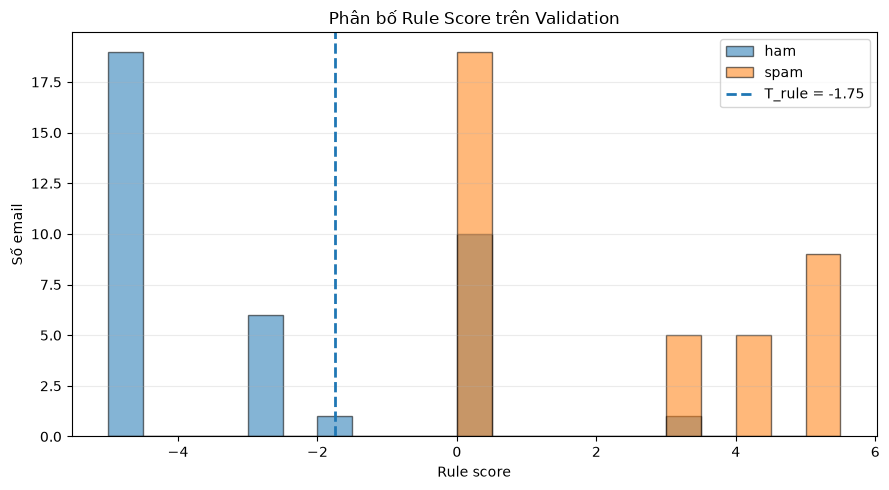

Đã lưu: C:\Users\kietn\Downloads\spam-emails-team-main\spam-emails-team\outputs\figures\rule_score_distribution.png


In [9]:
def plot_rule_score_distribution(val_scored_df, out_path):
    fig, ax = plt.subplots(figsize=(9, 5))
    for label in ["ham", "spam"]:
        values = val_scored_df.loc[
            val_scored_df["label"] == label, "rule_score"
        ]
        ax.hist(values, bins=[x / 2 for x in range(-10, 12)],
                alpha=0.55, label=label, edgecolor="black")
    ax.axvline(T_rule, linestyle="--", linewidth=2, label=f"T_rule = {T_rule:.2f}")
    ax.set_title("Phân bố Rule Score trên Validation")
    ax.set_xlabel("Rule score")
    ax.set_ylabel("Số email")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(out_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

rule_distribution_path = FIGURE_DIR / "rule_score_distribution.png"
plot_rule_score_distribution(val_scored_df, rule_distribution_path)
print("Đã lưu:", rule_distribution_path)

## 9. Chốt Validation và chấm Test một lần

Từ thời điểm này, bộ quy tắc và `T_rule` đã được cố định. Cell chỉ đọc Test để chấm điểm cuối cùng, không hiển thị nội dung email và không thay đổi quy tắc/ngưỡng dựa trên kết quả Test.

In [10]:
# Lưu kết quả Validation trước.
val_output_path = OUTPUT_DIR / "rule_val_scores.csv"
val_scored_df.to_csv(val_output_path, index=False, encoding="utf-8-sig")

# Đọc Test chỉ ở giai đoạn đánh giá cuối.
test_df = pd.read_csv(DATA_DIR / "test.csv")
test_scored_df = score_dataframe(test_df, rules)

test_output_path = OUTPUT_DIR / "rule_test_scores.csv"
test_scored_df.to_csv(test_output_path, index=False, encoding="utf-8-sig")

test_predictions = [
    "spam" if score >= T_rule else "ham"
    for score in test_scored_df["rule_score"]
]
test_metrics = evaluate(test_scored_df["label"].tolist(), test_predictions)

print("Đã chấm Test:", len(test_scored_df), "email")
print("Không sử dụng Test để thay đổi luật/ngưỡng.")
display(pd.DataFrame([test_metrics]).drop(columns=["warnings"]))
print("Đã lưu:", val_output_path)
print("Đã lưu:", test_output_path)

Đã chấm Test: 75 email
Không sử dụng Test để thay đổi luật/ngưỡng.


,total,tp,tn,fp,fn,accuracy,precision,recall,f1,fpr
0,75,37,33,5,0,0.9333,0.881,1.0,0.9367,0.1316


Đã lưu: C:\Users\kietn\Downloads\spam-emails-team-main\spam-emails-team\outputs\rule_val_scores.csv
Đã lưu: C:\Users\kietn\Downloads\spam-emails-team-main\spam-emails-team\outputs\rule_test_scores.csv


## 10. Báo cáo tóm tắt và xuất `rule_specification.md`

Tài liệu được tạo sau khi notebook chạy xong, dùng số liệu thực nghiệm thu được từ chính lần chạy này.

In [11]:
val_predictions = [
    "spam" if score >= T_rule else "ham"
    for score in val_scored_df["rule_score"]
]
val_metrics = evaluate(val_scored_df["label"].tolist(), val_predictions)

rule_lines = [
    "# Rule-based Classification Specification",
    "",
    "## 1. Phạm vi",
    "Phân loại email Spam/Ham bằng quy tắc từ khóa và cụm từ liền kề.",
    "",
    "## 2. Dữ liệu",
    f"- Train: {len(train_df)} email; chỉ dùng để khảo sát và xây dựng quy tắc.",
    f"- Validation: {len(val_df)} email; dùng chọn ngưỡng.",
    f"- Test: {len(test_df)} email; chỉ dùng đánh giá cuối.",
    "",
    "## 3. Quy tắc",
    f"- Tổng số quy tắc: {len(rules)}.",
    "- Spam có trọng số dương; Ham có trọng số âm.",
    "- Mỗi quy tắc chỉ được tính tối đa một lần trên mỗi email.",
    "- Điểm cuối được giới hạn trong [-5.0, +5.0].",
    "",
    "## 4. Ngưỡng",
    f"- T_rule được chọn trên Validation: **{T_rule:.2f}**.",
    "- Dự đoán Spam nếu rule_score >= T_rule; ngược lại dự đoán Ham.",
    "",
    "## 5. Kết quả Validation",
    f"- Accuracy: {val_metrics['accuracy']:.4f}",
    f"- Precision: {val_metrics['precision']:.4f}",
    f"- Recall: {val_metrics['recall']:.4f}",
    f"- F1-score: {val_metrics['f1']:.4f}",
    f"- FPR: {val_metrics['fpr']:.4f}",
    "",
    "## 6. Kết quả Test",
    f"- Accuracy: {test_metrics['accuracy']:.4f}",
    f"- Precision: {test_metrics['precision']:.4f}",
    f"- Recall: {test_metrics['recall']:.4f}",
    f"- F1-score: {test_metrics['f1']:.4f}",
    f"- FPR: {test_metrics['fpr']:.4f}",
    "",
    "## 7. Hạn chế",
    "- Bộ luật phụ thuộc vào từ khóa/cụm từ đã xuất hiện trong Train.",
    "- Email diễn đạt mới hoặc dùng từ đồng nghĩa có thể không khớp quy tắc.",
    "- Rule score là điểm phân loại, không phải xác suất Spam.",
    "",
    "## 8. Danh sách quy tắc",
    "",
    "| ID | Pattern | Weight | Description |",
    "|---|---|---:|---|"
]

for rule in rules:
    safe_pattern = rule["pattern"].replace("|", "\\|")
    safe_description = rule["description"].replace("|", "\\|")
    rule_lines.append(
        f"| {rule['id']} | `{safe_pattern}` | {rule['weight']:+.0f} | {safe_description} |"
    )

spec_path = DOCS_DIR / "rule_specification.md"
spec_path.write_text("\n".join(rule_lines) + "\n", encoding="utf-8")

print("Đã tạo:", spec_path)
print("Các đầu ra của nhiệm vụ Rule-based đã được sinh.")

Đã tạo: C:\Users\kietn\Downloads\spam-emails-team-main\spam-emails-team\docs\rule_specification.md
Các đầu ra của nhiệm vụ Rule-based đã được sinh.


## 11. Checklist hoàn thành

Sau khi chạy **Restart & Run All**, kiểm tra các file sau:
- `config/rules.json`
- `outputs/rule_val_scores.csv`
- `outputs/rule_test_scores.csv`
- `outputs/figures/rule_score_distribution.png`
- `docs/rule_specification.md`

Tiếp theo chạy unit test của dự án trong Terminal:

```bash
python -m unittest discover -s tests -v
```

Trước khi commit/push, xác nhận đang ở nhánh `kiet/rule-classification` và `git status` chỉ liệt kê các file thuộc quyền sở hữu của Nguyễn Kiệt. Không push lên `main`.